In [1]:
from langgraph.graph import StateGraph, START, END
from typing import TypedDict

### Define State

In [3]:
class StudentState(TypedDict):

    student_name: str
    marks: int
    attendance: int
    assignments_completed: int

    grade: str
    attendance_status: str
    assignment_status: str
    summary: str

### Creating Nodes
First Node: Calculate Grades

In [5]:
def calculate_grade(state: StudentState):

    marks = state['marks']

    if marks >= 80:
        grade = 'A'
    elif marks >= 70:
        grade = 'B'
    elif marks >= 60:
        grade = 'C'
    else:
        grade = 'D'

    return {
        'grade': grade
    }

Second Node: Check Attendance

In [6]:
def check_attendance(state: StudentState):

    if state['attendance'] >= 75:
        attendance_status = 'Good'
    else:
        attendance_status = 'Low'

    return {
        'attendance_status': attendance_status
    }

Third Node: Evaluate Assignments

In [7]:
def evaluate_assignments(state: StudentState):

    if state['assignments_completed'] >= 8:
        assignment_status = 'Excellent'
    else:
        assignment_status = 'Needs Improvement'

    return {
        'assignment_status': assignment_status
    }

Summary Node

In [8]:
def summary(state: StudentState):

    summary_text = (
        f"Student {state['student_name']} received grade {state['grade']}. "
        f"Attendance status is {state['attendance_status']}. "
        f"Assignment status is {state['assignment_status']}."
    )

    return {
        'summary': summary_text
    }

### Define and Compile Graph

In [9]:
# Define Graph
graph = StateGraph(StudentState)

# Add Nodes
graph.add_node('calculate_grade', calculate_grade)
graph.add_node('check_attendance', check_attendance)
graph.add_node('evaluate_assignments', evaluate_assignments)
graph.add_node('summary', summary)

# add edges
graph.add_edge(START, 'calculate_grade')
graph.add_edge(START, 'check_attendance')
graph.add_edge(START, 'evaluate_assignments')

graph.add_edge('calculate_grade', 'summary')
graph.add_edge('check_attendance', 'summary')
graph.add_edge('evaluate_assignments', 'summary')

graph.add_edge('summary', END)

# compile graph
workflow = graph.compile()

### Execute Graph

In [10]:
# intitial input
initial_state = {
    'student_name': 'Ali',
    'marks': 85,
    'attendance': 90,
    'assignments_completed': 9
}
# execute graph
result = workflow.invoke(initial_state)

result

{'student_name': 'Ali',
 'marks': 85,
 'attendance': 90,
 'assignments_completed': 9,
 'grade': 'A',
 'attendance_status': 'Good',
 'assignment_status': 'Excellent',
 'summary': 'Student Ali received grade A. Attendance status is Good. Assignment status is Excellent.'}

### Visualize graph

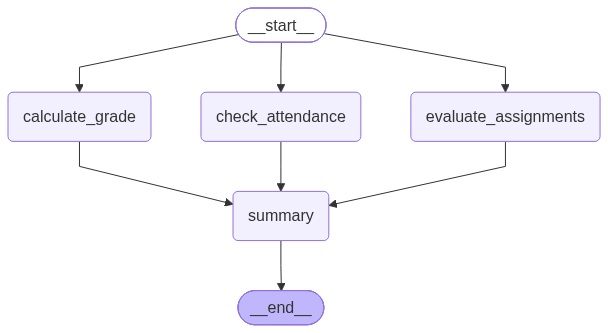

In [11]:
from IPython.display import Image
Image(workflow.get_graph().draw_mermaid_png())